# IADS5 · TP integrador — Ortelana Textil
### Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Integrantes del grupo:** Camila Belén Capua, Franco Salama, Juan Pablo Ruax Debruijn, Lorena Wajchman, Tomas Rossi y Miguel Ángel Tadakuma  
**Comisión:** [Completar]  
**Repositorio GitHub:** https://github.com/francosalama/paa-integrador-ortelana  
**Fecha:** 17/11/2026

> Notebook independiente. Requiere el archivo `particion_train_test.csv` (partición train/test generada por `actividad_01.ipynb`).

## Actividad 13 · Comparativa y modelo candidato · Parcial 2

**Qué se espera:** Construí la tabla completa de modelos con media CV, std CV y métrica test histórica. Elegí un candidato y justificá en al menos 200 palabras desempeño, estabilidad, interpretación, costo y mantenimiento. Verificá pipeline y cinco predicciones.

**Evidencia a entregar:** Notebooks 01–13; tabla; justificación; commit `entrega-parcial-2`; tag `parcial-2`.

### TODO — Implementación libre
Desarrollá una solución propia. Organizá tantas celdas como necesites; incluí tablas y gráficos con títulos, ejes y unidades cuando correspondan. No alcanza con que el código ejecute: debe permitir comprobar las consignas.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # avisos de versión de librerías
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

df = pd.read_csv("ventas_historicas_ortelana_argentina.csv")

# Partición de la actividad 01: misma semilla, mismas filas de train y test
target = "Format_Reporte"
features = ["Sucursal_ID", "Tela_ID", "Año", "Metros1", "Metros2"]
train, test = train_test_split(df, test_size=0.2, stratify=df[target], random_state=RANDOM_STATE)

# Control: tiene que coincidir con la partición guardada en particion_train_test.csv
particion = pd.read_csv("particion_train_test.csv", index_col="fila")["particion"]
assert (particion[test.index] == "test").all() and (particion == "test").sum() == len(test)

X_train, X_test = train[features], test[features]
y_train, y_test = train[target], test[target]

print("Train:", X_train.shape, "| Test:", X_test.shape)


Train: (2628, 5) | Test: (657, 5)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score
import time

cat_cols = ["Sucursal_ID", "Tela_ID"]
num_cols = ["Año", "Metros1", "Metros2"]

def crear_pipeline(modelo):
    """Actividades 05-08: one-hot + numéricas sin cambios."""
    preprocesador = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", "passthrough", num_cols)])
    return Pipeline([("prep", preprocesador), ("modelo", modelo)])

def crear_pipeline_completo(modelo, escalar=False):
    """Actividad 09 en adelante: imputación (+ escalado solo si el modelo lo necesita) / imputación + one-hot."""
    pasos_num = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    preprocesador = ColumnTransformer([
        ("num", Pipeline(pasos_num), num_cols),
        ("cat", Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
    return Pipeline([("preprocesamiento", preprocesador), ("modelo", modelo)])

def crear_pipeline_sin_ids(modelo, escalar=False):
    """Pipeline final: solo Año, Metros1 y Metros2 (imputación [+ escalado]). Sucursal_ID y Tela_ID se descartan."""
    pasos_num = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_num.append(("escalar", StandardScaler()))
    return Pipeline([("preprocesamiento", ColumnTransformer([("num", Pipeline(pasos_num), num_cols)])),
                     ("modelo", modelo)])

# Regresión logística de la actividad 03: solo las variables numéricas, escaladas
logit = Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), num_cols)])),
                  ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))])

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

# CV agrupada por par (Sucursal, Tela): ningún par aparece a la vez en entrenamiento y validación.
# Mide la generalización a combinaciones nuevas, que el split aleatorio no puede medir.
grupos = X_train["Sucursal_ID"].astype(str) + "|" + X_train["Tela_ID"]
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

In [3]:
# 13.1 Tabla completa: F1 macro de CV (10 folds, train), CV agrupada por par (5 folds, train) y test histórico
rf100 = lambda: RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
xgb100 = lambda: XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3,
                               random_state=RANDOM_STATE, n_jobs=-1, eval_metric="mlogloss")

# (modelo, usa Sucursal_ID y Tela_ID)
modelos = {
    "Baseline (clase más frecuente)": (DummyClassifier(strategy="most_frequent"), "no"),
    "Regresión logística (numéricas)": (logit, "no"),
    "Árbol gini (depth=4)": (crear_pipeline(DecisionTreeClassifier(criterion="gini", max_depth=4, random_state=RANDOM_STATE)), "sí"),
    "Árbol entropy (depth=4)": (crear_pipeline(DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=RANDOM_STATE)), "sí"),
    "Random Forest (100)": (crear_pipeline(rf100()), "sí"),
    "Pipeline completo + Random Forest (100)": (crear_pipeline_completo(rf100()), "sí"),
    "k-NN k=5 sin escalado": (crear_pipeline(KNeighborsClassifier(n_neighbors=5)), "sí"),
    "k-NN k=1 con escalado": (crear_pipeline_completo(KNeighborsClassifier(n_neighbors=1), escalar=True), "sí"),   # k de la actividad 11
    "XGBoost (100, lr=0.1, depth=3)": (crear_pipeline(xgb100()), "sí"),
    # Mismos modelos SIN identificadores: solo Año, Metros1 y Metros2
    "Random Forest (100) sin identificadores": (crear_pipeline_sin_ids(rf100()), "no"),
    "k-NN k=5 con escalado sin identificadores": (crear_pipeline_sin_ids(KNeighborsClassifier(n_neighbors=5), escalar=True), "no"),
    "XGBoost (100, lr=0.1, depth=3) sin identificadores": (crear_pipeline_sin_ids(xgb100()), "no"),
}

# XGBoost necesita las clases como números: se codifican para entrenar y se decodifican al predecir
codificador = LabelEncoder().fit(y_train)

def evaluar(nombre, modelo):
    """CV estratificada aleatoria, CV agrupada por par y métrica de test histórica."""
    es_xgb = nombre.startswith("XGBoost")
    y_entrenamiento = codificador.transform(y_train) if es_xgb else y_train
    inicio = time.perf_counter()
    scores = cross_val_score(modelo, X_train, y_entrenamiento, cv=cv10, scoring="f1_macro")
    tiempo = time.perf_counter() - inicio
    scores_grupo = cross_val_score(modelo, X_train, y_entrenamiento, cv=cv_grupos, groups=grupos, scoring="f1_macro")
    pred = modelo.fit(X_train, y_entrenamiento).predict(X_test)
    pred = codificador.inverse_transform(pred) if es_xgb else pred
    return {"F1 macro CV media": scores.mean(), "F1 macro CV desvío": scores.std(),
            "F1 macro CV por grupos (pares nuevos)": scores_grupo.mean(),
            "F1 macro CV por grupos desvío": scores_grupo.std(),
            "F1 macro test": f1_score(y_test, pred, average="macro"),
            "Accuracy test": accuracy_score(y_test, pred), "Tiempo CV (s)": tiempo}

filas = [{"Modelo": nombre, "Usa Sucursal/Tela": usa_ids, **evaluar(nombre, modelo)}
         for nombre, (modelo, usa_ids) in modelos.items()]

tabla = pd.DataFrame(filas).set_index("Modelo").sort_values("F1 macro CV por grupos (pares nuevos)", ascending=False)
tabla["caída al pasar a pares nuevos"] = tabla["F1 macro CV media"] - tabla["F1 macro CV por grupos (pares nuevos)"]
tabla.round(4)

,Usa Sucursal/Tela,F1 macro CV media,F1 macro CV desvío,F1 macro CV por grupos (pares nuevos),F1 macro CV por grupos desvío,F1 macro test,Accuracy test,Tiempo CV (s),caída al pasar a pares nuevos
Modelo,,,,,,,,,
k-NN k=5 sin escalado,sí,0.9126,0.0149,0.8805,0.0262,0.9162,0.9148,0.1955,0.0320
Random Forest (100) sin identificadores,no,0.8632,0.0198,0.8392,0.0292,0.8657,0.8630,1.6924,0.0240
k-NN k=5 con escalado sin identificadores,no,0.8459,0.0198,0.8279,0.0320,0.8453,0.8432,0.1130,0.0180
"XGBoost (100, lr=0.1, depth=3) sin identificadores",no,0.8446,0.0195,0.8041,0.0187,0.8555,0.8539,2.7938,0.0405
Regresión logística (numéricas),no,0.7104,0.0298,0.7100,0.0256,0.7296,0.7336,0.2255,0.0004
k-NN k=1 con escalado,sí,0.9859,0.0062,0.6981,0.0573,0.9941,0.9939,0.1770,0.2878
Random Forest (100),sí,0.9654,0.0109,0.6625,0.0270,0.9751,0.9756,1.7098,0.3029
"XGBoost (100, lr=0.1, depth=3)",sí,0.8698,0.0219,0.6564,0.0322,0.8877,0.8889,3.0162,0.2134
Pipeline completo + Random Forest (100),sí,0.9649,0.0109,0.6430,0.0226,0.9706,0.9711,1.7231,0.3219


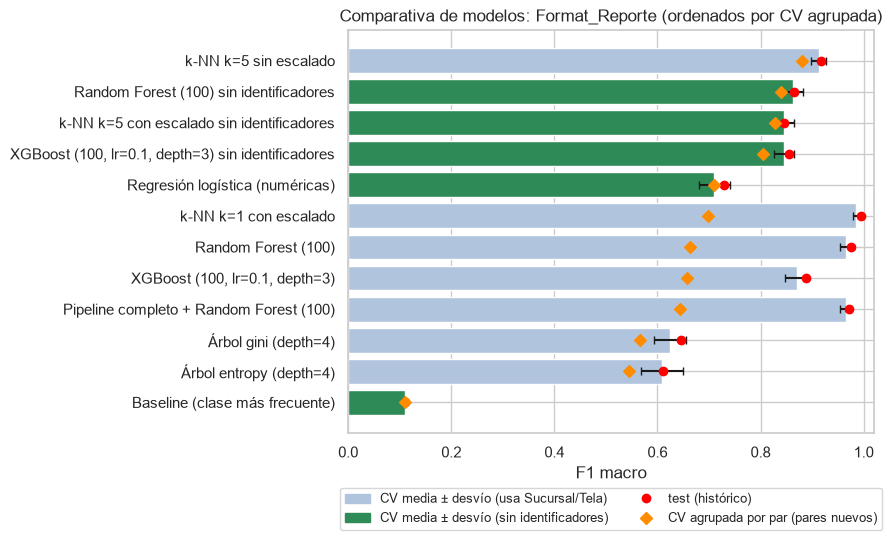

In [4]:
# 13.2 Visualización de la comparativa (media ± desvío de CV y test)
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

orden = tabla.sort_values("F1 macro CV por grupos (pares nuevos)")
colores = orden["Usa Sucursal/Tela"].map({"sí": "lightsteelblue", "no": "seagreen"})
plt.figure(figsize=(9, 5.6))
plt.barh(orden.index, orden["F1 macro CV media"], xerr=orden["F1 macro CV desvío"], color=colores, capsize=3)
plt.scatter(orden["F1 macro test"], orden.index, color="red", zorder=3)
plt.scatter(orden["F1 macro CV por grupos (pares nuevos)"], orden.index, color="darkorange", marker="D", zorder=3)
plt.title("Comparativa de modelos: Format_Reporte (ordenados por CV agrupada)")
plt.xlabel("F1 macro")
plt.xlim(0, 1.02)
plt.legend(handles=[Patch(color="lightsteelblue", label="CV media ± desvío (usa Sucursal/Tela)"),
                    Patch(color="seagreen", label="CV media ± desvío (sin identificadores)"),
                    Line2D([], [], color="red", marker="o", ls="", label="test (histórico)"),
                    Line2D([], [], color="darkorange", marker="D", ls="", label="CV agrupada por par (pares nuevos)")],
           loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

In [5]:
# 13.3 Modelo candidato: Random Forest sin identificadores (solo Año, Metros1 y Metros2)
from sklearn.base import clone

candidato = modelos["Random Forest (100) sin identificadores"][0]   # ya entrenado en 13.1
print("Pasos del pipeline:", [paso for paso, _ in candidato.steps])
print("Columnas que usa el modelo:", list(candidato.named_steps["preprocesamiento"].get_feature_names_out()))

# Verificación 1: reentrenar desde cero da exactamente las mismas predicciones
otro = clone(candidato).fit(X_train, y_train)
print("Mismas predicciones al reentrenar:", (otro.predict(X_test) == candidato.predict(X_test)).all())

# Verificación 2: la predicción no depende de Sucursal ni Tela (cambiarlas no cambia nada)
cinco = X_test.head(5)
cambiado = cinco.assign(Sucursal_ID=99, Tela_ID="TELA-999")
print("Predicciones iguales con otra sucursal y tela:", (candidato.predict(cambiado) == candidato.predict(cinco)).all())

# Cinco predicciones de prueba con sus probabilidades
resultado = cinco.copy()
resultado["real"] = y_test.head(5)
resultado["predicción"] = candidato.predict(cinco)
probabilidades = pd.DataFrame(candidato.predict_proba(cinco), index=cinco.index,
                              columns=[f"P({c})" for c in candidato.classes_])
pd.concat([resultado, probabilidades.round(2)], axis=1)

Pasos del pipeline: ['preprocesamiento', 'modelo']
Columnas que usa el modelo: ['num__Año', 'num__Metros1', 'num__Metros2']
Mismas predicciones al reentrenar: True


Predicciones iguales con otra sucursal y tela: True


,Sucursal_ID,Tela_ID,Año,Metros1,Metros2,real,predicción,P(B),P(C),P(M),P(S)
1127,5,TELA-001,2016,292.35,308.44,M,M,0.17,0.00,0.8,0.03
365,2,TELA-006,2018,2682.03,2106.97,C,C,0.00,0.81,0.0,0.19
1109,4,TELA-009,2025,1575.90,1150.65,C,C,0.00,0.87,0.0,0.13
1318,5,TELA-006,2023,1114.15,1152.13,S,S,0.16,0.19,0.0,0.65
2583,10,TELA-018,2019,1003.58,773.20,C,C,0.00,0.90,0.0,0.10


### Explicación del alumno/a

**Decisiones técnicas y justificación:**
- **Tabla:** reúne todos los modelos de clasificación con tres mediciones:
  - la misma CV estratificada de 10 folds sobre train (media y std), que es la que pide la consigna;
  - una **CV agrupada por par (Sucursal, Tela)** de 5 folds sobre train (`StratifiedGroupKFold`, media y std): ningún par aparece a la vez en entrenamiento y validación, así que mide qué pasa con combinaciones nuevas;
  - el F1 macro de test "histórico" y el tiempo de la CV.
- **Por qué agregamos la CV agrupada:** el formato es constante para cada par y el 100% de los pares de test está en train (Actividad 01). Con un split aleatorio, cualquier modelo que use `Sucursal_ID` y `Tela_ID` puede acertar recordando el par.
- **Modelos sin identificadores:** agregamos Random Forest, k-NN (k = 5, con escalado) y XGBoost entrenados **solo con `Año`, `Metros1` y `Metros2`**. La columna "Usa Sucursal/Tela" distingue los dos grupos y la tabla queda ordenada por la CV agrupada.
- **Criterio de selección (devolución del docente):** si el par (Sucursal, Tela) es conocido, no hace falta machine learning: el formato es constante por par y alcanza con buscarlo en el histórico. El modelo solo aporta valor para **pares nuevos**, así que lo elegimos **sin identificadores** y con la **CV agrupada** como métrica de selección.

**Interpretación de los resultados:**
- **Con la CV aleatoria (la de la consigna)** ganan los modelos con identificadores: k-NN k = 1 (0,986), RF (0,965) y Pipeline RF (0,965).
- **Con la CV agrupada por par, esos modelos se desploman:** k-NN k = 1 cae a **0,698** (−0,29), RF a 0,663 (−0,30), XGBoost a 0,656 (−0,21) y el Pipeline RF a **0,643** (−0,32). Con el split aleatorio **memorizan** el formato fijo de cada par.
- **Los modelos sin identificadores casi no cambian:** RF 0,863 → **0,839** (−0,02), k-NN k = 5 escalado 0,846 → 0,828 y XGBoost 0,845 → 0,804. Su desempeño viene del volumen, que sí se traslada a pares nuevos.
- **Caso particular:** k-NN k = 5 *sin escalado* obtiene 0,881 en la CV agrupada aunque recibe los identificadores. Sin escalar, los metros (cientos o miles) dominan la distancia y las dummies (0 o 1) casi no pesan, así que en la práctica es un modelo de volumen. Lo descartamos porque usa los identificadores y porque su comportamiento depende de una escala accidental, no de una decisión de diseño.

**Candidato elegido: Random Forest (100 árboles) sin identificadores** (`Año`, `Metros1`, `Metros2`).
- **Desempeño:** el mejor modelo sin identificadores en la CV agrupada (**0,839 ± 0,029**), por delante de k-NN k = 5 (0,828) y XGBoost (0,804). Con la CV aleatoria obtiene 0,863 y en test 0,866: las tres mediciones son coherentes porque ya no hay memoria de pares que las infle.
- **Estabilidad:** desvío de 0,020 en la CV aleatoria y 0,029 en la agrupada, similar al resto de los candidatos sin identificadores. La diferencia con k-NN (0,011) está dentro de un desvío, así que la elección se apoya también en los puntos siguientes.
- **Interpretación:** ofrece importancias de variables y **probabilidades graduadas** por clase, que permiten derivar a revisión las predicciones inciertas. k-NN no tiene importancias y depende de la escala.
- **Robustez y simplicidad:** imputa faltantes, no necesita escalado (es invariante a la escala, Actividad 09) y tiene margen de mejora con hiperparámetros, que exploramos en la Actividad 14.
- **Costo y mantenimiento:** entrena en menos de un segundo, predice en milisegundos y es un único objeto de scikit-learn serializable con joblib. No necesita codificar el target, como XGBoost (`LabelEncoder`).
- **Verificación (13.3):**
  - el pipeline usa solo `Año`, `Metros1` y `Metros2`;
  - reconstruido con `clone` reproduce exactamente sus predicciones;
  - cambiar la sucursal y la tela de los registros (sucursal 99, `TELA-999`) no cambia ninguna predicción;
  - las cinco predicciones de prueba son correctas, con probabilidades de entre 0,65 y 0,90 en la clase elegida.

**Pregunta de análisis:** ¿Por qué elegís este modelo y no el que tiene la mejor métrica aislada?
- Porque la mejor métrica aislada (k-NN k = 1, 0,986) mide memoria de pares conocidos, no generalización: la CV agrupada lo muestra (0,698). Y para pares conocidos, el modelo no hace falta: el formato se obtiene del histórico. Elegimos el modelo que mejor rinde en el único escenario donde el modelo aporta valor, el de pares nuevos.
- **Vínculo con la teoría:** la Unidad 6 asocia k = 1 con varianza alta y sobreajuste. La Unidad 5 indica elegir "por rendimiento, estabilidad y costo, no solo por el máximo F1", y la validación debe imitar el uso real: si el uso real son pares nuevos, la CV tiene que agrupar por par.

**Limitaciones o mejoras posibles:**
- Las métricas de la CV aleatoria y del test siguen evaluando pares conocidos. Para el modelo sin identificadores el sesgo es chico (0,863 contra 0,839), pero la CV agrupada es la referencia.
- Consultar el test en cada actividad, como pide el enunciado, ya expuso ese conjunto. Por eso la elección se basa en la CV y no en la columna de test.

### Comentarios del docente

[Espacio breve para observaciones sobre esta actividad: aciertos, correcciones o sugerencias.]